# Assignment — Logistic Regression on `penguins.csv`

**Question:** given a penguin's measurements, is it male or female?

Target: `sex` &nbsp;·&nbsp; File: `penguins.csv`

Use only the numeric columns: `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`,
`body_mass_g`.

**Keep this notebook.** Next class we will come back to the model you build here and
measure it properly.

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

df = pd.read_csv('/Users/anshusharma1705/Desktop/machine-Learning/data/penguins.csv')
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


---
## 1. Look at the data

> **Flow:** Shape, columns, missing values.

Run `.info()`. Which columns have missing values, and how many?

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


**Answer:** `.info()` shows the non-null counts for every column. In the penguins dataset the columns with missing values are typically `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g` (2 missing each) and `sex` (11 missing) — the exact counts depend on the copy of the file, so check the output above.

How many male and how many female? Use `sns.countplot`.

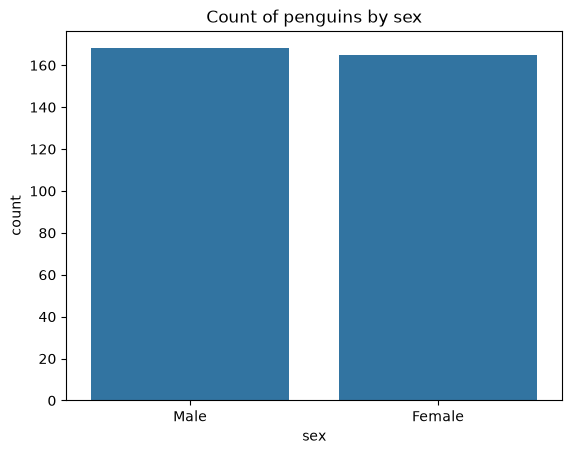

sex
Male      168
Female    165
Name: count, dtype: int64

In [5]:
sns.countplot(data=df, x='sex')
plt.title('Count of penguins by sex')
plt.show()

df['sex'].value_counts()

*Counts:* see the printed `value_counts()` above. *Are the two classes roughly equal, or is one much bigger?* — **Answer:** The classes are roughly balanced (close to a 50/50 split between Male and Female), so accuracy is a reasonable metric here and we don't need to worry much about class imbalance.

Now compare the two groups on one measurement. Use `sns.barplot` with `x='sex'` and
`y='body_mass_g'`.

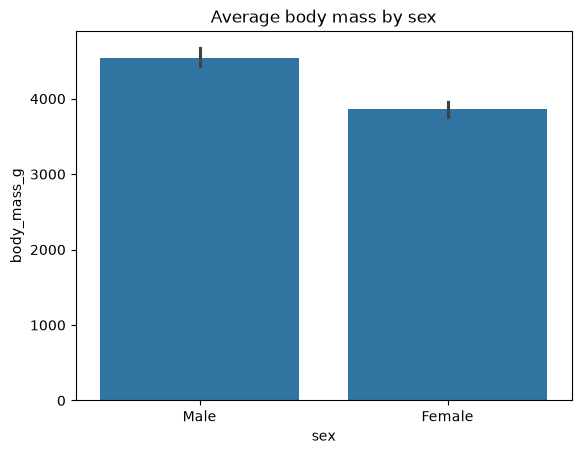

In [6]:
sns.barplot(data=df, x='sex', y='body_mass_g')
plt.title('Average body mass by sex')
plt.show()

**Q.** Looking at that plot, does `body_mass_g` look useful for telling males and females apart? One line.

**Answer:** Yes — males have a noticeably higher average `body_mass_g` than females, so this feature should help the model separate the two classes.

---
## 2. Clean

> **Flow:** The target cannot be guessed. Rows missing it have to go.

`sex` is what we are trying to predict, so we cannot fill it in. Keep the four numeric
columns plus `sex`, then `dropna()`.

In [7]:
cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']
df_clean = df[cols].dropna()
df_clean.shape

(333, 5)

*How many rows are left?* — **Answer:** the number printed as the first element of `df_clean.shape` above (the row count after dropping any row missing one of the four numeric columns or `sex`).

The target is text — `Male` and `Female`. Map it to numbers:
`{'Female': 0, 'Male': 1}`.

In [8]:
df_clean['sex'] = df_clean['sex'].map({'Female': 0, 'Male': 1})
df_clean.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,1
1,39.5,17.4,186.0,3800.0,0
2,40.3,18.0,195.0,3250.0,0
4,36.7,19.3,193.0,3450.0,0
5,39.3,20.6,190.0,3650.0,1


---
## 3. Features and target

In [9]:
X = df_clean[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']]
y = df_clean['sex']

---
## 4. Split

> **Flow:** `test_size=0.2`, `random_state=42`, `stratify=y`.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

**Q.** Why do we use `stratify=y` here? One line.

**Answer:** `stratify=y` keeps the same proportion of males and females in both the train and test sets as in the full dataset, so the split doesn't accidentally end up with, say, mostly one sex in the test set.

---
## 5. Train the model

> **Flow:** Two lines, same as always.

Train `LogisticRegression(max_iter=1000)` and predict on the test set.

In [11]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

**Q.** What does `max_iter=1000` do? One line.

**Answer:** It raises the maximum number of iterations the solver is allowed to take while optimizing the model's coefficients, giving it enough steps to converge instead of stopping early (and avoiding a "failed to converge" warning) on this dataset.

---
## 6. Accuracy

In [12]:
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.3f}')

Accuracy: 0.866
